# Forecasting staple food prices in northeast Nigeria

**Question.** How far ahead, and how accurately, can market prices for staple foods in Borno and Yobe states be forecast from the price record alone?

**Why it matters.** Borno and Yobe are at the centre of a long-running humanitarian crisis, and millions of people there depend on markets and cash assistance to eat. When prices jump, a fixed cash transfer buys less food. Agencies set transfer values and pre-position stock months ahead, so a credible three-month price forecast with honest uncertainty bands is directly useful. The period covered here also includes one of the sharpest food price shocks in Nigeria's recent history, after the petrol subsidy was removed and the naira was floated in mid 2023.

**Data.** [WFP food prices for Nigeria](https://data.humdata.org/dataset/wfp-food-prices-for-nigeria), published by the World Food Programme on the Humanitarian Data Exchange. Real monthly market prices collected by WFP monitors, updated continuously.

**What this notebook does**

1. Loads and cleans the market price records
2. Builds consistent monthly price series
3. Describes the price shock, seasonality and what it did to purchasing power
4. Tests a machine learning forecaster against simple baselines with a rolling backtest
5. Quantifies forecast uncertainty from the backtest and checks that the bands hold up out of sample
6. Turns the forecast into a planning tool for cash transfer values and exports everything for the live dashboard

## 1. Setup

In [1]:
import json
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import xgboost as xgb

warnings.filterwarnings("ignore")
SEED = 42
ROOT = Path("..")
RAW = ROOT / "data" / "raw"
APP = ROOT / "docs" / "data"
RAW.mkdir(parents=True, exist_ok=True)
APP.mkdir(parents=True, exist_ok=True)

BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#77766f"
plt.rcParams.update({
    "figure.figsize": (8, 4.2), "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e9e8e3", "axes.axisbelow": True, "font.size": 10,
})

## 2. Load the data

The file is downloaded from the Humanitarian Data Exchange and cached. Each row is one price observation: a commodity, in a market, in a month.

In [2]:
URL = ("https://data.humdata.org/dataset/42db041f-7aaf-4ab4-961f-2a12096861e7/resource/"
       "12b51155-0cd3-4806-9924-61ede4077591/download/wfp_food_prices_nga.csv")
csv_path = RAW / "wfp_food_prices_nga.csv"
if not csv_path.exists():
    csv_path.write_bytes(requests.get(URL, timeout=180).content)

raw = pd.read_csv(csv_path, parse_dates=["date"])
print(f"{len(raw):,} price records, {raw['date'].min():%b %Y} to {raw['date'].max():%b %Y}")
print(f"{raw['market'].nunique()} markets in {raw['admin1'].nunique()} states, {raw['commodity'].nunique()} commodities")
raw.head(3)

91,216 price records, Jan 2002 to Nov 2026
68 markets in 14 states, 43 commodities


,date,admin1,admin2,market,market_id,latitude,longitude,category,commodity,commodity_id,unit,priceflag,pricetype,currency,price,usdprice
0,2002-01-15,Katsina,Jibia,Jibia (CBM),1038,13.08,7.24,cereals and tubers,Maize,51,KG,actual,Wholesale,NGN,175.92,1.54
1,2002-01-15,Katsina,Jibia,Jibia (CBM),1038,13.08,7.24,cereals and tubers,Millet,73,KG,actual,Wholesale,NGN,150.18,1.31
2,2002-01-15,Katsina,Jibia,Jibia (CBM),1038,13.08,7.24,cereals and tubers,Rice (imported),64,KG,actual,Wholesale,NGN,358.70,3.14


## 3. Understanding coverage

Before analysing anything, check where and when the data is dense enough to support a monthly series.

In [3]:
retail = raw[raw["pricetype"] == "Retail"].copy()
coverage = retail.groupby("admin1").agg(records=("price", "size"), markets=("market", "nunique"),
                                        first=("date", "min"), last=("date", "max")).sort_values("records", ascending=False)
coverage

,records,markets,first,last
admin1,,,,
Borno,30104,28,2014-07-15,2026-11-15
Yobe,27725,18,2015-01-15,2026-11-15
Kaduna,1840,2,2014-07-15,2023-01-15
Adamawa,1700,7,2015-01-15,2025-11-15
Oyo,1039,1,2014-05-15,2023-01-15
Kebbi,996,1,2014-07-15,2023-01-15
Gombe,992,1,2014-07-15,2023-01-15
Jigawa,968,1,2014-07-15,2023-01-15
Zamfara,950,1,2014-07-15,2023-01-15


Coverage is very uneven. Borno and Yobe have dozens of monitored markets and records up to the present, because that is where WFP runs its operations. Most other states have a single market and stop in early 2023.

**Scope decision.** The analysis is restricted to retail prices in **Borno and Yobe from January 2017**, which is the period and place where the data is complete enough to trust. Results should not be read as national figures.

In [4]:
STATES = ["Borno", "Yobe"]
START = "2017-01-01"
ne = retail[retail["admin1"].isin(STATES) & (retail["date"] >= START) & (retail["currency"] == "NGN") & (retail["price"] > 0)].copy()
ne["month"] = ne["date"].dt.to_period("M").dt.to_timestamp()
units = ne.groupby("commodity")["unit"].agg(lambda s: s.mode()[0])
ne = ne[ne["unit"] == ne["commodity"].map(units)]

months_total = ne["month"].nunique()
presence = ne.groupby(["commodity", "admin1"])["month"].nunique().unstack()
keep = presence[(presence.min(axis=1) >= 0.8 * months_total)].index.tolist()
keep = [c for c in keep if not c.startswith("Fuel")]
ne_food = ne[ne["commodity"].isin(keep)]
print(f"{len(keep)} food commodities with at least 80% monthly coverage in both states:")
print(", ".join(f"{c} ({units[c]})" for c in keep))

23 food commodities with at least 80% monthly coverage in both states:
Bananas (1.3 KG), Beans (red) (2.5 KG), Beans (white) (2.5 KG), Eggs (30 pcs), Fish (KG), Groundnuts (2.2 KG), Maize flour (2.1 KG), Meat (beef) (KG), Meat (goat) (KG), Milk (powder) (400 G), Millet (2.6 KG), Oil (palm) (L), Oil (vegetable) (L), Onions (0.5 KG), Oranges (400 G), Rice (imported) (2.8 KG), Rice (local) (2.7 KG), Salt (250 G), Sorghum (2.7 KG), Sugar (500 G), Tomatoes (0.5 KG), Watermelons (2.1 KG), Yam (2.5 KG)


## 4. Building monthly series

Several markets report each month, and individual quotes can be noisy (a typing error, an unusual trader). For each commodity, state and month the **median across markets** is used, which is robust to a few bad quotes. Gaps of up to three months are filled by linear interpolation in log prices. Longer gaps are left empty.

Two extra series are built from the same file because they are plausible drivers of food prices:

* the **exchange rate**, implied by the naira and US dollar prices WFP records for every observation
* the **petrol price**, which drives transport costs

In [5]:
prices = ne_food.groupby(["commodity", "admin1", "month"])["price"].median().unstack(["commodity", "admin1"]).sort_index()
all_months = pd.date_range(prices.index.min(), prices.index.max(), freq="MS")
prices = prices.reindex(all_months)
log_prices = np.log(prices).interpolate(limit=3, limit_area="inside")
prices = np.exp(log_prices)

with_usd = raw[(raw["usdprice"] > 0) & (raw["currency"] == "NGN") & (raw["date"] >= START)].copy()
with_usd["month"] = with_usd["date"].dt.to_period("M").dt.to_timestamp()
fx = (with_usd["price"] / with_usd["usdprice"]).groupby(with_usd["month"]).median().reindex(all_months).interpolate().ffill().bfill()

petrol_rows = raw[(raw["commodity"] == "Fuel (petrol-gasoline)") & (raw["date"] >= START) & (raw["price"] > 0)].copy()
petrol_rows["month"] = petrol_rows["date"].dt.to_period("M").dt.to_timestamp()
petrol = petrol_rows.groupby("month")["price"].median().reindex(all_months).interpolate().ffill().bfill()

category = ne_food.groupby("commodity")["category"].agg(lambda s: s.mode()[0])
print(f"{prices.shape[1]} series, {prices.shape[0]} months, {prices.isna().mean().mean():.1%} of cells still missing after interpolation")

46 series, 119 months, 4.3% of cells still missing after interpolation


## 5. Exploratory analysis

### The 2023 to 2024 price shock

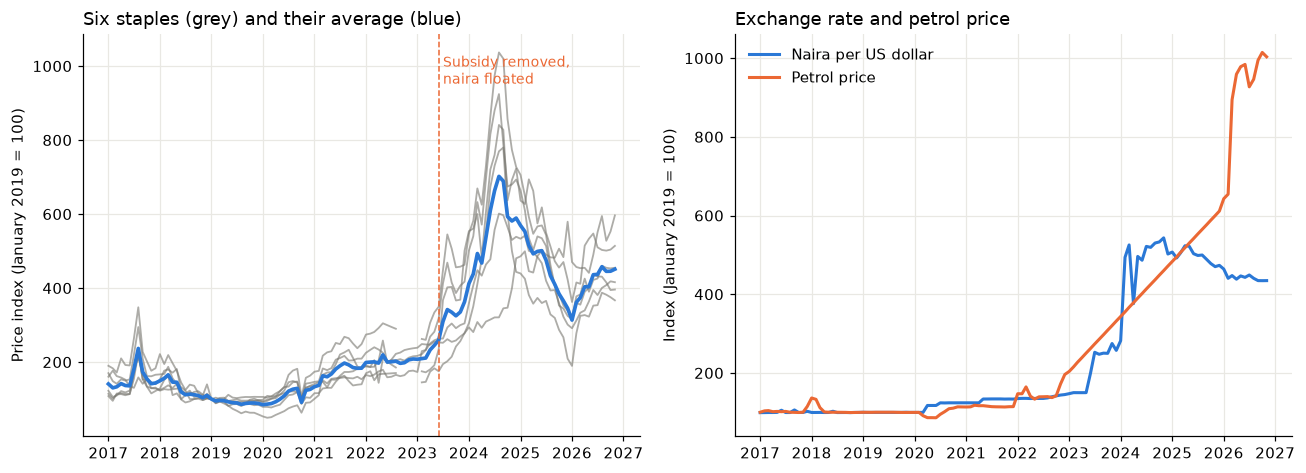

Staple index: 245 in May 2023, peak 702 in August 2024, latest 451 in November 2026
Change from May 2023 to peak: +186%
Change from peak to latest:   -36%


In [6]:
STAPLES = [c for c in ["Rice (local)", "Millet", "Sorghum", "Maize flour", "Beans (white)", "Oil (palm)"] if c in keep]
state_avg = np.exp(log_prices.T.groupby(level="commodity").mean().T)
base_month = "2019-01-01"
index = state_avg[STAPLES] / state_avg[STAPLES].loc[base_month] * 100
basket = np.exp(np.log(index).mean(axis=1))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
for commodity in STAPLES:
    axes[0].plot(index.index, index[commodity], lw=1.2, color=GREY, alpha=0.6)
axes[0].plot(basket.index, basket, lw=2.4, color=BLUE)
axes[0].axvline(pd.Timestamp("2023-06-01"), color=ORANGE, ls="--", lw=1)
axes[0].text(pd.Timestamp("2023-07-01"), axes[0].get_ylim()[1] * 0.95, "Subsidy removed,\nnaira floated", color=ORANGE, fontsize=9, va="top")
axes[0].set_ylabel("Price index (January 2019 = 100)")
axes[0].set_title("Six staples (grey) and their average (blue)", loc="left")

axes[1].plot(fx.index, fx / fx.loc[base_month] * 100, color=BLUE, lw=2, label="Naira per US dollar")
axes[1].plot(petrol.index, petrol / petrol.loc[base_month] * 100, color=ORANGE, lw=2, label="Petrol price")
axes[1].set_ylabel("Index (January 2019 = 100)")
axes[1].set_title("Exchange rate and petrol price", loc="left")
axes[1].legend(frameon=False)
plt.tight_layout()
plt.show()

peak = basket.idxmax()
print(f"Staple index: {basket.loc['2023-05-01']:.0f} in May 2023, peak {basket.max():.0f} in {peak:%B %Y}, latest {basket.iloc[-1]:.0f} in {basket.index[-1]:%B %Y}")
print(f"Change from May 2023 to peak: {basket.max() / basket.loc['2023-05-01'] - 1:+.0%}")
print(f"Change from peak to latest:   {basket.iloc[-1] / basket.max() - 1:+.0%}")

Staple prices had been rising steadily since 2019, then accelerated sharply after mid 2023, when the petrol subsidy ended and the naira lost most of its value against the dollar. The right-hand panel shows both shocks arriving at the same time. Prices peaked and have since come down from that peak, but they remain several times their 2019 level.

### What a day's minimum wage buys

Index numbers hide what this means for a household. A more direct measure is how many kilograms of local rice one day of the national minimum wage can buy. The monthly minimum wage was 18,000 naira until April 2019, then 30,000 naira, then 70,000 naira from July 2024.

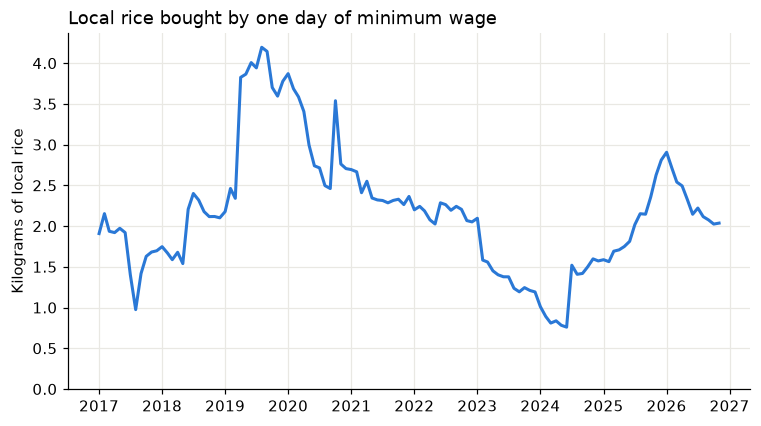

2019 average: 3.5 kg   lowest: 0.8 kg in June 2024   latest: 2.0 kg


In [7]:
def minimum_wage(month):
    if month < pd.Timestamp("2019-04-01"):
        return 18_000
    if month < pd.Timestamp("2024-07-01"):
        return 30_000
    return 70_000


rice_unit_kg = float(units["Rice (local)"].split()[0])
rice_per_kg = state_avg["Rice (local)"] / rice_unit_kg
daily_wage = pd.Series([minimum_wage(m) / 30 for m in rice_per_kg.index], index=rice_per_kg.index)
rice_kg_per_day = daily_wage / rice_per_kg

fig, ax = plt.subplots()
ax.plot(rice_kg_per_day.index, rice_kg_per_day, color=BLUE, lw=2)
ax.set_ylabel("Kilograms of local rice")
ax.set_title("Local rice bought by one day of minimum wage", loc="left")
ax.set_ylim(0)
plt.show()
print(f"2019 average: {rice_kg_per_day.loc['2019'].mean():.1f} kg   lowest: {rice_kg_per_day.min():.1f} kg in {rice_kg_per_day.idxmin():%B %Y}   latest: {rice_kg_per_day.iloc[-1]:.1f} kg")

Purchasing power fell steeply through the shock and only recovered when the minimum wage was raised in July 2024 and prices began to ease. The step up in the line is the wage increase.

### Seasonality

In the Sahel, cereal prices typically rise through the lean season (roughly June to August, before the harvest) and fall after the harvest (October to December). The chart shows the average month-on-month price change by calendar month for cereals, using years before the 2023 shock so the pattern is not swamped by it.

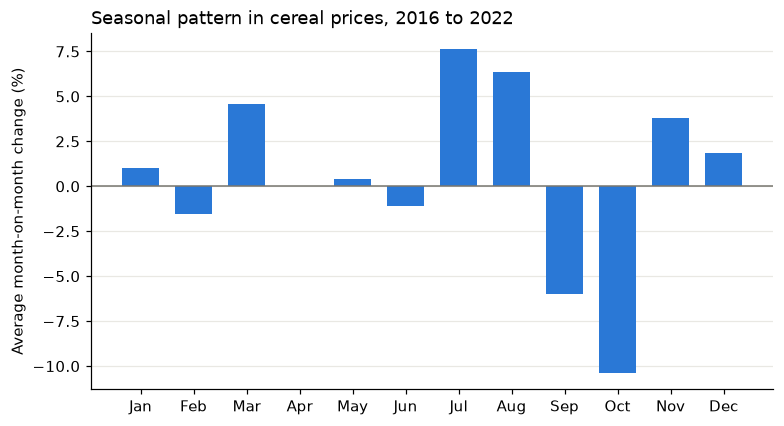

In [8]:
cereals = [c for c in ["Millet", "Sorghum", "Maize flour", "Rice (local)"] if c in keep]
monthly_change = np.log(state_avg[cereals]).diff().loc[:"2022-12-01"].mean(axis=1) * 100
seasonal = monthly_change.groupby(monthly_change.index.month).mean()
fig, ax = plt.subplots()
ax.bar(["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"], seasonal.values, color=BLUE, width=0.7)
ax.axhline(0, color=GREY, lw=1)
ax.set_ylabel("Average month-on-month change (%)")
ax.set_title("Seasonal pattern in cereal prices, 2016 to 2022", loc="left")
ax.grid(axis="x", visible=False)
plt.show()

The lean-season pattern is clear: cereal prices rose by six to eight percent a month on average in July and August, then fell sharply in September and October as the harvest came in. The forecasting model is given the calendar month so it can use this.

## 6. Forecasting approach

**Target.** For each series (a commodity in a state) and each month, predict the **change in log price** over the next 1, 2 and 3 months. Predicting the change rather than the level makes a 300 naira item and a 5,000 naira item comparable, so one model can learn from all series at once.

**Three candidates**

* **No change**: the price in one, two or three months equals today's price. This is the random walk forecast. It sounds naive, but for prices it is famously hard to beat.
* **Drift**: prices keep changing at their own average monthly rate over the last 12 months.
* **Gradient boosted model**: one XGBoost model per horizon, trained across all series on the features below.

| Feature | Meaning |
|---|---|
| `r1`, `r3`, `r6`, `r12` | The series' own price change over the last 1, 3, 6 and 12 months (momentum) |
| `dev3`, `dev12` | Current price relative to its own 3 and 12-month average (is it stretched, or was the last quote a blip?) |
| `spread` | Price in this state relative to the other state for the same commodity (neighbouring markets tend to converge) |
| `vol6` | Volatility of the last six monthly changes |
| `mkt_r1`, `mkt_r3` | Average price change across all series (general food inflation) |
| `fx_r1`, `fx_r3`, `fx_r12` | Change in the exchange rate |
| `fuel_r1`, `fuel_r3`, `fuel_r12` | Change in the petrol price |
| `month_sin`, `month_cos` | Calendar month of the target, for seasonality |
| `cat_*`, `borno` | Food category and state |

**Validation.** A rolling-origin backtest over the last 36 months. The model is refitted every six months using only data that would have been available at that time, then asked to forecast the following six months. Nothing from the future leaks into training. The model settings were fixed in advance and were not tuned on the backtest.

In [9]:
series_keys = list(prices.columns)
categories = sorted(category.loc[keep].unique())
BASE_FEATURES = ["r1", "r3", "r6", "r12", "dev3", "dev12", "spread", "vol6", "mkt_r1", "mkt_r3",
                 "fx_r1", "fx_r3", "fx_r12", "fuel_r1", "fuel_r3", "fuel_r12", "borno"] + [f"cat_{i}" for i in range(len(categories))]
FEATURES = BASE_FEATURES + ["month_sin", "month_cos"]
HORIZONS = [1, 2, 3]

lfx, lfuel = np.log(fx), np.log(petrol)
mkt_r1 = log_prices.diff(1).mean(axis=1)
mkt_r3 = log_prices.diff(3).mean(axis=1)

rows = []
for commodity, state in series_keys:
    lp = log_prices[(commodity, state)]
    f = pd.DataFrame(index=lp.index)
    f["r1"], f["r3"], f["r6"], f["r12"] = lp.diff(1), lp.diff(3), lp.diff(6), lp.diff(12)
    f["dev3"] = lp - lp.rolling(3).mean()
    f["dev12"] = lp - lp.rolling(12).mean()
    f["spread"] = lp - log_prices[commodity].mean(axis=1)
    f["vol6"] = lp.diff().rolling(6).std()
    f["mkt_r1"], f["mkt_r3"] = mkt_r1, mkt_r3
    f["fx_r1"], f["fx_r3"], f["fx_r12"] = lfx.diff(1), lfx.diff(3), lfx.diff(12)
    f["fuel_r1"], f["fuel_r3"], f["fuel_r12"] = lfuel.diff(1), lfuel.diff(3), lfuel.diff(12)
    f["borno"] = int(state == "Borno")
    for i, name in enumerate(categories):
        f[f"cat_{i}"] = int(category[commodity] == name)
    f["drift"] = lp.diff(12) / 12
    f["lp"] = lp
    for h in HORIZONS:
        f[f"y{h}"] = lp.shift(-h) - lp
    f["commodity"], f["state"], f["month"] = commodity, state, lp.index
    rows.append(f)
panel = pd.concat(rows, ignore_index=True)
panel = panel.dropna(subset=["r12", "dev12", "vol6", "lp"]).reset_index(drop=True)
panel["category"] = panel["commodity"].map(category)


def design(frame, h):
    target_month = (frame["month"].dt.month - 1 + h) % 12
    return frame[BASE_FEATURES].assign(month_sin=np.sin(2 * np.pi * target_month / 12), month_cos=np.cos(2 * np.pi * target_month / 12))


print(f"{len(panel):,} series-months with full features, {panel['month'].min():%b %Y} to {panel['month'].max():%b %Y}")

4,253 series-months with full features, Jan 2018 to Nov 2026


In [10]:
def fit(train, h):
    train = train.dropna(subset=[f"y{h}"])
    model = xgb.XGBRegressor(n_estimators=300, learning_rate=0.03, max_depth=3, min_child_weight=10, subsample=0.8,
                             colsample_bytree=0.8, reg_lambda=5.0, objective="reg:absoluteerror", random_state=SEED, n_jobs=4)
    return model.fit(design(train, h), train[f"y{h}"])


last_month = panel["month"].max()
origins = pd.date_range(last_month - pd.DateOffset(months=35), last_month, freq="6MS")
results = []
for start in origins:
    end = start + pd.DateOffset(months=6)
    test = panel[(panel["month"] >= start) & (panel["month"] < end)]
    for h in HORIZONS:
        train = panel[panel["month"] + pd.DateOffset(months=h) < start]
        model = fit(train, h)
        scored = test.dropna(subset=[f"y{h}"])
        results.append(pd.DataFrame({
            "commodity": scored["commodity"], "state": scored["state"], "category": scored["category"], "month": scored["month"],
            "horizon": h, "actual": scored[f"y{h}"], "model": model.predict(design(scored, h)),
            "no_change": 0.0, "drift": scored["drift"] * h,
        }))
backtest = pd.concat(results, ignore_index=True)
print(f"{len(backtest):,} out-of-sample forecasts across {len(origins)} refits, {backtest['month'].min():%b %Y} to {backtest['month'].max():%b %Y}")

4,476 out-of-sample forecasts across 6 refits, Dec 2023 to Oct 2026


## 7. Backtest results

Error is the **mean absolute percentage error (MAPE)** of the forecast price against the price that actually occurred. The median error is also shown, because a few wild months can dominate a mean.

In [11]:
def mape(actual, predicted):
    return float(np.mean(np.abs(np.exp(predicted - actual) - 1)) * 100)


def median_ape(actual, predicted):
    return float(np.median(np.abs(np.exp(predicted - actual) - 1)) * 100)


table = []
for h in HORIZONS:
    part = backtest[backtest["horizon"] == h]
    row = {"horizon (months)": h, "forecasts": len(part)}
    for label, column in [("No change", "no_change"), ("Drift", "drift"), ("Gradient boosting", "model")]:
        row[f"{label} MAPE"] = mape(part["actual"], part[column])
    for label, column in [("No change", "no_change"), ("Gradient boosting", "model")]:
        row[f"{label} median error"] = median_ape(part["actual"], part[column])
    table.append(row)
accuracy = pd.DataFrame(table).set_index("horizon (months)")
accuracy.round(2)

,forecasts,No change MAPE,Drift MAPE,Gradient boosting MAPE,No change median error,Gradient boosting median error
horizon (months),,,,,,
1,1538,11.57,12.54,11.92,5.64,6.09
2,1492,16.84,19.91,16.99,8.81,9.46
3,1446,19.94,25.28,21.32,11.74,13.01


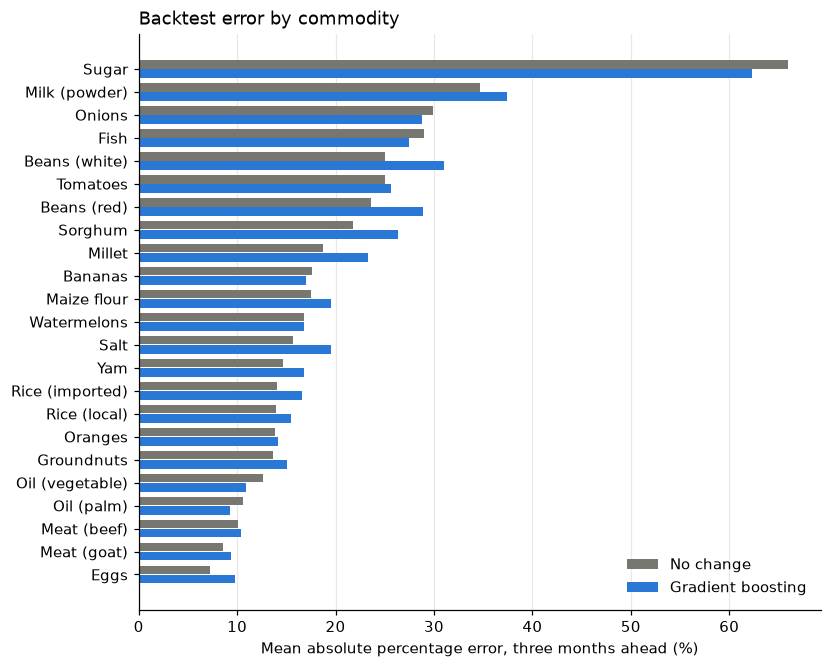

Gradient boosting beats no change for 6 of 23 commodities at three months


In [12]:
by_commodity = []
for commodity, part in backtest[backtest["horizon"] == 3].groupby("commodity"):
    by_commodity.append({"commodity": commodity, "No change": mape(part["actual"], part["no_change"]), "Gradient boosting": mape(part["actual"], part["model"])})
by_commodity = pd.DataFrame(by_commodity).set_index("commodity").sort_values("No change")

fig, ax = plt.subplots(figsize=(8, 6.8))
positions = np.arange(len(by_commodity))
ax.barh(positions + 0.2, by_commodity["No change"], height=0.38, color=GREY, label="No change")
ax.barh(positions - 0.2, by_commodity["Gradient boosting"], height=0.38, color=BLUE, label="Gradient boosting")
ax.set_yticks(positions, by_commodity.index)
ax.set_xlabel("Mean absolute percentage error, three months ahead (%)")
ax.set_title("Backtest error by commodity", loc="left")
ax.legend(frameon=False)
ax.grid(axis="y", visible=False)
plt.show()
wins = int((by_commodity["Gradient boosting"] < by_commodity["No change"]).sum())
print(f"Gradient boosting beats no change for {wins} of {len(by_commodity)} commodities at three months")

**The machine learning model does not beat the no-change forecast.** The two are close at every horizon, the model is never clearly ahead, and it wins for only a minority of commodities. The drift rule is clearly worse than both.

This is a real result and worth stating plainly, for three reasons:

1. **Prices in these markets behave close to a random walk.** Once today's price is known, the features add little. Momentum, the exchange rate and petrol prices explain where prices have been much better than where they go next.
2. **The backtest window is a regime change.** The model learned from years in which prices mostly rose, then was tested on a period in which they surged, peaked and fell. Momentum learned on the way up is a liability on the way down. The drift rule fails for the same reason, only more so.
3. **Simple is safer.** A humanitarian planner is better served by a transparent rule with honest error bars than by a complex model that does no better.

I also tried the same approach on individual markets instead of state medians, with a feature for each market's gap to the state price. It did not beat no change there either. I stopped at that point: trying variants until one happens to win on the test window would be fitting to the test set.

**Decision.** The deployed point forecast is the no-change forecast. The useful question then becomes: how wrong can it be?

## 8. How uncertain is the forecast?

The backtest gives thousands of real out-of-sample price changes, so uncertainty bands can be read straight from them without assuming any distribution. For each food category and horizon, the 10th and 90th percentiles of the price changes define an **80 percent interval**.

Bands like this are only worth publishing if they hold up on data they were not built from. So the check is done in two halves: bands are estimated on the **first 18 months** of the backtest, and their coverage is measured on the **last 18 months**. If the method works, about 80 percent of later actual prices should fall inside.

In [13]:
midpoint = origins[len(origins) // 2]
early = backtest[backtest["month"] < midpoint]
late = backtest[backtest["month"] >= midpoint]
early_bands = early.groupby(["category", "horizon"])["actual"].quantile([0.1, 0.9]).unstack()
early_bands.columns = ["low", "high"]
checked = late.join(early_bands, on=["category", "horizon"])
checked["inside"] = (checked["actual"] >= checked["low"]) & (checked["actual"] <= checked["high"])
coverage_check = checked.groupby("horizon")["inside"].agg(coverage="mean", forecasts="size")
coverage_check["below band"] = (checked["actual"] < checked["low"]).groupby(checked["horizon"]).mean()
coverage_check["above band"] = (checked["actual"] > checked["high"]).groupby(checked["horizon"]).mean()
print(f"Bands estimated on forecasts before {midpoint:%B %Y}, checked on forecasts from then on (target 0.80):")
coverage_check.round(3)

Bands estimated on forecasts before June 2025, checked on forecasts from then on (target 0.80):


,coverage,forecasts,below band,above band
horizon,,,,
1,0.848,782,0.091,0.061
2,0.840,736,0.117,0.043
3,0.825,690,0.133,0.042


Bands estimated on the earlier period contained 82 to 85 percent of the later actual prices, close to the 80 percent they were built for. The misses lean to the low side: prices fell below the band more often than they rose above it, because the later period was one of easing prices while the bands were learned in a rising one. For a planner worried about under-budgeting, that is the safer direction to be wrong in. The final bands below use the full 36 months.

In [14]:
bands = backtest.groupby(["category", "horizon"])["actual"].quantile([0.1, 0.5, 0.9]).unstack()
bands.columns = ["low", "median", "high"]
(np.exp(bands) - 1).mul(100).round(1).rename(columns={"low": "lower band (%)", "median": "median change (%)", "high": "upper band (%)"})

lower band (%)  median change (%)  \
category              horizon                                      
cereals and tubers    1                 -12.5                0.0   
                      2                 -18.1                0.2   
                      3                 -21.4                0.1   
meat, fish and eggs   1                  -7.3                0.9   
                      2                  -9.4                2.2   
                      3                 -10.6                3.6   
milk and dairy        1                  -6.7                0.0   
                      2                  -6.2                0.0   
                      3                  -5.9                0.0   
miscellaneous food    1                  -9.9                0.0   
                      2                 -15.3                0.0   
                      3                 -24.3                0.0   
oil and fats          1                  -7.9                1.8   
                      2                 -10.1                1.9   
                      3                 -11.9                4.4   
pulses and nuts       1                 -11.4                0.5   
                      2                 -19.3               -0.2   
                      3                 -26.7                2.1   
vegetables and fruits 1                 -17.2                0.0   
                      2                 -22.3                0.0   
                      3                 -21.1                2.7   

                               upper band (%)  
category              horizon                  
cereals and tubers    1                  14.8  
                      2                  21.6  
                      3                  33.6  
meat, fish and eggs   1                  15.7  
                      2                  25.6  
                      3                  33.1  
milk and dairy        1                   9.2  
                      2                  11.8  
                      3                  14.3  
miscellaneous food    1                  11.1  
                      2                  33.4  
                      3                 100.0  
oil and fats          1                  14.8  
                      2                  24.0  
                      3                  31.9  
pulses and nuts       1                  15.4  
                      2                  28.0  
                      3                  43.7  
vegetables and fruits 1                  27.8  
                      2                  41.7  
                      3                  50.0

Each row gives the range within which 80 percent of actual price changes fell for that food category and horizon. Bands widen with the horizon, and they differ a lot between categories.

## 9. What did the model try to use?

Even though the model is not deployed, its feature attributions show what it found in the data.

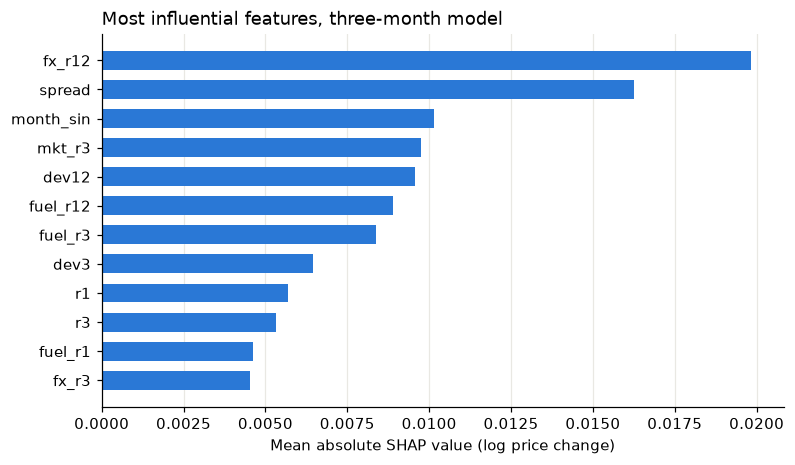

In [15]:
final_model = fit(panel, 3)
with_target = panel.dropna(subset=["y3"])
contrib = final_model.get_booster().predict(xgb.DMatrix(design(with_target, 3)), pred_contribs=True)[:, :-1]
importance = pd.Series(np.abs(contrib).mean(axis=0), index=FEATURES)
importance = importance.groupby(lambda name: "food category" if name.startswith("cat_") else name).sum().sort_values(ascending=False)
top = importance.head(12)[::-1]
fig, ax = plt.subplots(figsize=(8, 4.4))
ax.barh(top.index, top.values, color=BLUE, height=0.65)
ax.set_xlabel("Mean absolute SHAP value (log price change)")
ax.set_title("Most influential features, three-month model", loc="left")
ax.grid(axis="y", visible=False)
plt.show()

## 10. Outlook for the next three months

The point forecast is the latest price. The band is the 80 percent interval from the backtest for that food category and horizon.

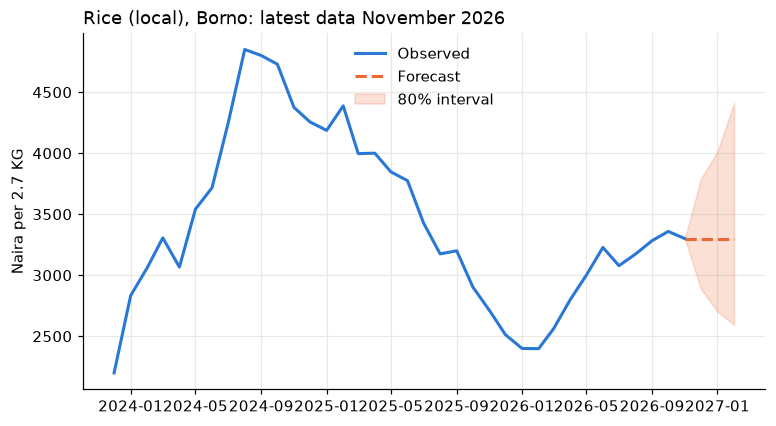

,month,forecast,low,high
32,2026-12-01,3300.0,2889.0,3790.0
78,2027-01-01,3300.0,2701.0,4013.0
124,2027-02-01,3300.0,2594.0,4410.0


In [16]:
latest = panel[panel["month"] == last_month]
forecast_rows = []
for h in HORIZONS:
    for _, row in latest.iterrows():
        band = bands.loc[(row["category"], h)]
        price = float(np.exp(row["lp"]))
        forecast_rows.append({"commodity": row["commodity"], "state": row["state"], "horizon": h,
                              "month": row["month"] + pd.DateOffset(months=h), "forecast": price,
                              "low": price * float(np.exp(band["low"])), "high": price * float(np.exp(band["high"]))})
forecasts = pd.DataFrame(forecast_rows)

example = ("Rice (local)", "Borno")
history = prices[example].dropna().iloc[-36:]
fc = forecasts[(forecasts["commodity"] == example[0]) & (forecasts["state"] == example[1])]
fig, ax = plt.subplots()
ax.plot(history.index, history, color=BLUE, lw=2, label="Observed")
ax.plot([history.index[-1], *fc["month"]], [history.iloc[-1], *fc["forecast"]], color=ORANGE, lw=2, ls="--", label="Forecast")
ax.fill_between([history.index[-1], *fc["month"]], [history.iloc[-1], *fc["low"]], [history.iloc[-1], *fc["high"]], color=ORANGE, alpha=0.2, label="80% interval")
ax.set_ylabel(f"Naira per {units[example[0]]}")
ax.set_title(f"{example[0]}, {example[1]}: latest data {last_month:%B %Y}", loc="left")
ax.legend(frameon=False)
plt.show()
fc[["month", "forecast", "low", "high"]].round(0)

### From forecast to decision: sizing a cash transfer

Suppose an agency gives households a monthly cash transfer meant to buy a fixed food basket. A transfer set at today's prices will fall short whenever prices rise. Pricing each item at its upper band gives a buffer that would have been enough in roughly nine months out of ten for every item individually. Because items do not all hit their upper band at once, this is a deliberately cautious figure for the basket as a whole. The example uses a simple monthly basket for one person.

In [17]:
BASKET = {"Rice (local)": 4, "Millet": 4, "Beans (white)": 2, "Oil (palm)": 1}
basket_rows = []
for state in STATES:
    now = sum(qty * float(prices[(item, state)].dropna().iloc[-1]) for item, qty in BASKET.items())
    upper = sum(qty * float(prices[(item, state)].dropna().iloc[-1]) * float(np.exp(bands.loc[(category[item], 3), "high"])) for item, qty in BASKET.items())
    basket_rows.append({"state": state, "cost today (naira)": now, "cost at upper band in 3 months (naira)": upper, "buffer needed (%)": (upper / now - 1) * 100})
print("Basket:", ", ".join(f"{qty} x {item} ({units[item]})" for item, qty in BASKET.items()))
pd.DataFrame(basket_rows).set_index("state").round(0)

Basket: 4 x Rice (local) (2.7 KG), 4 x Millet (2.6 KG), 2 x Beans (white) (2.5 KG), 1 x Oil (palm) (L)


,cost today (naira),cost at upper band in 3 months (naira),buffer needed (%)
state,,,
Borno,25950.0,35131.0,35.0
Yobe,23200.0,31455.0,36.0


## 11. Export for the live dashboard

In [18]:
def clean(values, digits=2):
    return [None if pd.isna(v) else round(float(v), digits) for v in values]


months = [m.strftime("%Y-%m") for m in prices.index]
series_out = [{"commodity": c, "state": s, "unit": units[c], "category": category[c], "prices": clean(prices[(c, s)])} for c, s in series_keys]
yoy = (prices.iloc[-1] / prices.iloc[-13] - 1).mul(100)
summary = {
    "months": months,
    "latest_month": last_month.strftime("%Y-%m"),
    "series": series_out,
    "fx": clean(fx), "petrol": clean(petrol),
    "basket": clean(basket), "staples": STAPLES,
    "rice_kg_per_day": clean(rice_kg_per_day),
    "seasonal": clean(seasonal.values, 3),
    "accuracy": json.loads(accuracy.reset_index().to_json(orient="records")),
    "by_commodity": json.loads(by_commodity.reset_index().to_json(orient="records")),
    "coverage": json.loads(coverage_check.reset_index().to_json(orient="records")),
    "bands": [{"category": c, "horizon": int(h), "low": float(r["low"]), "median": float(r["median"]), "high": float(r["high"])} for (c, h), r in bands.iterrows()],
    "yoy": [{"commodity": c, "state": s, "change": None if pd.isna(v) else round(float(v), 1)} for (c, s), v in yoy.items()],
    "default_basket": BASKET,
    "markets": int(ne_food["market"].nunique()), "records": int(len(ne_food)),
    "backtest_forecasts": int(len(backtest)),
    "shock": {"may_2023": float(basket.loc["2023-05-01"]), "peak": float(basket.max()), "peak_month": basket.idxmax().strftime("%Y-%m"), "latest": float(basket.iloc[-1])},
}
(APP / "summary.json").write_text(json.dumps(summary, separators=(",", ":")))
print("summary.json", round((APP / "summary.json").stat().st_size / 1024), "KB")

summary.json 52 KB


## 12. Conclusions

* Staple food prices in Borno and Yobe nearly tripled between May 2023 and their peak in August 2024, after the petrol subsidy was removed and the naira was floated. They have fallen by about a third since but remain more than four times their January 2019 level. At the trough, a day of minimum wage bought less than a quarter of the rice it bought in 2019.
* A gradient boosted model using momentum, general inflation, the exchange rate, petrol prices and seasonality **did not beat the simple assumption that prices stay where they are**, in a 36-month rolling backtest with no tuning on the test window. The same held at market level.
* The practical output is therefore the no-change forecast with empirical 80 percent bands by food category and horizon. Checked out of sample, the bands covered 82 to 85 percent of actual prices.
* The bands are wide: for cereals, plus 33 percent to minus 21 percent at three months. That width is the main message for planners. Budgeting a cash transfer against the upper band rather than today's price gives a concrete, defensible buffer of about 35 percent for the example basket.

**Limitations**

* The data covers markets that WFP monitors in two states. It is not a national picture, and monitored markets are not a random sample.
* Medians across markets hide local spikes, for example in a town cut off by insecurity or flooding.
* The backtest period is unusual. In a calmer period a model might add more, and the bands would be narrower.
* No price-only model can foresee a policy shock such as the 2023 subsidy removal.

**Next steps.** Test leading indicators from outside the price record, such as rainfall (CHIRPS), conflict events (ACLED) and border closures, which are the most plausible route to beating the random walk. Recalibrate the bands on a rolling window, and extend the transfer calculator to the full survival minimum expenditure basket.